# DBLP Conference Mining Team 7 Notebook

Objective: Menemukan popularitas konferensi dan pola asosiasi antar-konferensi dari publikasi inproceedings DBLP tahun 2015-2025 dengan Frequent Pattern Mining (Apriori dan FP-Growth) dan Association Rule Mining, diukur dengan support, confidence, dan lift.

# Sinkronisasi versi modules dan libraries

In [1]:
import sys
print(sys.version)
%pip install -q pandas==2.3.3 numpy==2.4.4 matplotlib==3.10.9 lxml==6.1.3 pyarrow==24.0.0 scipy==1.17.1 mlxtend==0.25.0

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\leouw\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


# Import modules dan libraries

In [2]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from EDA import conference_popularity_analysis as popularity
from EDA import data_understanding_preprocessing as eda
from Evaluation import algorithm_performance_comparison as evaluation
from Modelling import association_rule_mining as arm
from Modelling import frequent_pattern_mining as fpm
from Modelling import temporal_association_analysis as temporal
from Preparation import transactional_database_construction as prep

pd.set_option("display.max_colwidth", 120, "display.precision", 4)
plt.rcParams["figure.dpi"] = 110

# Import datasets

### Sumber dataset
Mengunduh dump XML resmi DBLP (`dblp.xml.gz`) beserta DTD-nya dari https://dblp.org/xml/ lalu mencatat tanggal pengambilan, karena dump di server diganti secara berkala.

In [3]:
metadata = eda.download_dblp()
print(json.dumps(metadata, indent=2))

{
  "retrieved_at": "2026-11-16 14:46 UTC",
  "source": "https://dblp.org/xml/dblp.xml.gz",
  "dtd": "https://dblp.org/xml/dblp.dtd",
  "size_bytes": 1120379370,
  "last_modified": "Sun, 15 Nov 2026 22:40:21 GMT"
}


### Ekstraksi XML
Membaca dump secara streaming dalam satu kali baca: semua jenis record dihitung, tetapi hanya record `inproceedings` yang disimpan apa adanya ke parquet agar setiap keputusan pembersihan terlihat di tahap preprocessing.

In [4]:
raw, dump_summary = eda.extract_dblp()
print(f"Jumlah record inproceedings mentah: {len(raw):,}")
raw.head()

Jumlah record inproceedings mentah: 4,001,131


,key,mdate,title,year,booktitle,authors
0,series/sapere/Freed13,2022-10-02,Practical Introspection as Inspiration for AI.,2011,PT-AI,[Sam Freed]
1,series/sapere/Steiner13,2023-03-21,C.S. Peirce and Artificial Intelligence: Historical Heritage and (New) Theoretical Stakes.,2011,PT-AI,[Pierre Steiner]
2,series/sapere/Sandberg13,2019-09-06,Feasibility of Whole Brain Emulation.,2011,PT-AI,[Anders Sandberg]
3,series/sapere/BerkeleyR13,2023-09-30,Machine Mentality?,2011,PT-AI,"[Istvan S. N. Berkeley, Claiborne Rice]"
4,series/sapere/NasutoB13,2025-09-06,Of (Zombie) Mice and Animats.,2011,PT-AI,"[Slawomir J. Nasuto, John Mark Bishop]"


# EDA

### Jenis publikasi
Dump DBLP adalah satu file XML berisi daftar record, dan nama tag setiap record menyatakan jenis publikasinya.

In [5]:
eda.record_type_table(dump_summary)

,records,share_%
publication_type,,
article,4519980,34.47
www,4242364,32.35
inproceedings,4001131,30.51
phdthesis,158395,1.21
incollection,71264,0.54
proceedings,65856,0.50
data,31430,0.24
book,21654,0.17
mastersthesis,27,0.00


### Atribut inproceedings
Atribut yang tersedia pada record `inproceedings` dan berapa persen record yang memilikinya.

In [6]:
eda.attribute_table(dump_summary, "inproceedings")

,records,coverage_%
attribute,,
title,4001131,100.00
year,4001131,100.00
url,4001131,100.00
booktitle,4000810,99.99
crossref,3998522,99.93
author,3995049,99.85
ee,3863752,96.57
pages,3771703,94.27
stream,182833,4.57


### Missing values
Mengecek nilai kosong pada atribut yang dipakai untuk analisis: key, title, year, booktitle (venue), dan author.

In [7]:
eda.missing_value_table(raw)

,missing,missing_%
attribute,,
key,0,0.000
title,0,0.000
year,0,0.000
booktitle,321,0.008
authors,6082,0.152


### Struktur dataset
- Dump berisi 13.112.101 record: 4.519.980 `article` (jurnal), 4.242.364 `www` (halaman profil author, bukan publikasi), dan 4.001.131 `inproceedings` (paper konferensi dan workshop, 30,51%).
- Setiap record `inproceedings` punya `key` unik (contoh `conf/nips/...`) yang memuat stream venue, serta atribut `title`, `year`, `booktitle`, dan nol atau lebih `author`.
- Atribut yang dipakai: `key`, `author`, `title`, `year`, `booktitle`. Atribut lain (`url`, `ee`, `pages`, `crossref`) tidak relevan untuk popularitas dan pola asosiasi.
- Missing values sangat sedikit: 6.082 record tanpa author (0,152%) dan 321 tanpa booktitle (0,008%), sedangkan title dan year selalu terisi.

### Preprocessing
Membersihkan record mentah menjadi tabel `papers` (satu baris per publikasi) dan `authorship` (satu baris per pasangan publikasi dan author).
- select conference/workshop: hanya mengambil record `inproceedings`, karena itu jenis record DBLP untuk paper konferensi dan workshop.
- year consistency: `year` diubah menjadi integer dan hanya 2015-2025 yang dipakai, agar tahun bisa dibandingkan sebagai angka dan sesuai periode pengamatan.
- missing values: record tanpa author, booktitle, atau title dibuang, karena tanpa author atau venue record tidak bisa menjadi transaksi dan jumlahnya terlalu kecil untuk memengaruhi hasil.
- venue normalisation: identitas venue diambil dari stream pada `key` (`conf/nips`), sehingga NIPS dan NeurIPS, "ECCV (17)", dan "ACL (Findings)" terhitung sebagai satu conference. Booktitle tidak dipakai langsung karena penulisannya berubah antar tahun dan volume.
- author normalisation: normalisasi Unicode (NFKC) dan spasi. Sufiks homonim DBLP seperti "Wei Wang 0001" dipertahankan karena itu penanda orang yang berbeda, kalau dihapus ribuan peneliti akan tergabung menjadi satu author.
- duplicates: membuang record dengan key yang sama, atau dengan judul, daftar author, venue, dan tahun yang sama.

In [8]:
papers, authorship, preprocessing_log = eda.preprocess(raw, n_dump_records=sum(dump_summary["record_types"].values()))
eda.save_processed(papers, authorship)
preprocessing_log

,step,rows_before,rows_after,removed,note
0,select conference/workshop,13112101,4001131,9110970,kept record type inproceedings
1,year consistency,4001131,2004019,1997112,"year cast to integer, kept 2015-2025"
2,missing values,2004019,2001574,2445,"dropped records without author, booktitle or title"
3,venue normalisation,2001574,2001574,0,"8,903 booktitles -> 4,515 venues"
4,author normalisation,2001574,2001574,0,"1,822,238 raw names -> 1,822,238 authors"
5,duplicates,2001574,2000367,1207,"same normalised title, author set, venue and year"


In [9]:
papers.head()

,key,title,year,venue,stream,booktitle,n_authors
0,conf/dac/RoquetSRTSK24,Cross-Layer Reliability Evaluation and Efficient Hardening of Large Vision Transformers Models.,2024,DAC,conf/dac,DAC,6
1,conf/dac/LiuZWCYHYJ22,SATO: spiking neural network acceleration via temporal-oriented dataflow and architecture.,2022,DAC,conf/dac,DAC,8
2,conf/dac/AhnYLHKP20,Hawkware: Network Intrusion Detection based on Behavior Analysis with ANNs on an IoT Device.,2020,DAC,conf/dac,DAC,6
3,conf/dac/ParkPVC24,Accelerating DTCO with a Sample-Efficient Active Learning Framework for TCAD Device Modeling.,2024,DAC,conf/dac,DAC,4
4,conf/dac/PuL0HLC024,Lesyn: Placement-aware Logic Resynthesis for Non-Integer Multiple-Cell-Height Designs.,2024,DAC,conf/dac,DAC,7


### Hasil preprocessing
- Filter tahun adalah langkah yang paling banyak membuang data: dari 4.001.131 inproceedings tersisa 2.004.019 yang terbit pada 2015-2025.
- 2.445 record dibuang karena missing values dan 1.207 karena duplikat, keduanya di bawah 0,2% data.
- 8.903 penulisan booktitle menyatu menjadi 4.515 venue.
- Jumlah nama author tidak berubah setelah normalisasi (1.822.238), artinya nama author di DBLP sudah konsisten dan disambiguasi oleh DBLP sendiri.

### Statistik dataset

In [10]:
eda.dataset_statistics(papers, authorship).to_frame()

,value
total publications,2000367
unique authors,1822238
unique venues,4515
author-paper pairs,7878710
mean authors per paper,3.94
first year,2015
last year,2025


### Distribusi publikasi per tahun

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
publications,161287,162112,168110,176579,188760,172032,178443,178340,201711,213557,199436


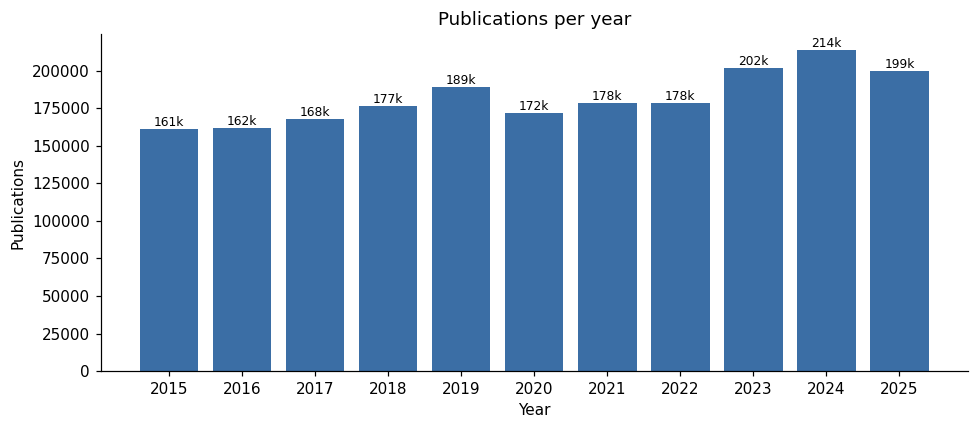

In [11]:
eda.plot_publications_per_year(papers)
eda.publications_per_year(papers).to_frame().T

### Distribusi publikasi per conference
Ukuran venue sangat timpang, jadi histogram memakai skala log pada sumbu x.

,count,mean,std,min,25%,50%,75%,max
publications,4515.0,443.0492,1333.1225,1.0,31.0,126.0,383.0,25455.0


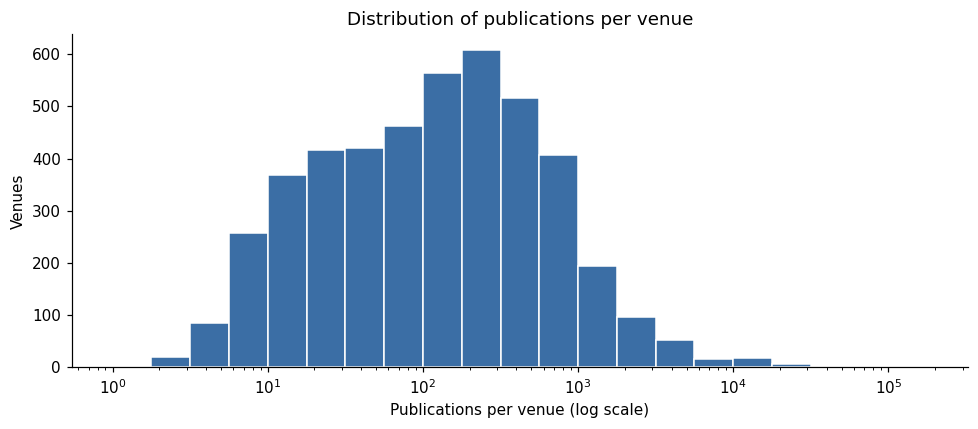

In [12]:
eda.plot_venue_size_distribution(papers)
eda.publications_per_venue(papers).describe().to_frame().T

### Analisis statistik dataset
- Dataset akhir berisi 2.000.367 publikasi, 1.822.238 author unik, dan 4.515 venue, dengan rata-rata 3,94 author per paper.
- Publikasi per tahun naik dari 161.287 (2015) menjadi 213.557 (2024). Tahun 2020 turun ke 172.032, bertepatan dengan pandemi.
- Angka 2025 (199.436) lebih rendah dari 2024 karena sebagian prosiding 2025 belum masuk DBLP saat dump diambil, contohnya IGARSS dan EMBC yang belum punya data 2025.
- Distribusi per conference sangat timpang: median venue hanya 126 publikasi selama 11 tahun, rata-rata 443, sedangkan yang terbesar 25.455. Sebagian kecil conference besar mendominasi jumlah publikasi.

### Top 10 conference
Popularitas diukur dari aktivitas publikasi: jumlah publikasi dan jumlah author unik per conference.

,publications,rank_publications
venue,,
NeurIPS,25455,1
CVPR,22752,2
ICASSP,21606,3
HCI,19912,4
IGARSS,19685,5
AAAI,19276,6
CHI,14834,7
EMNLP,14814,8
EMBC,14677,9


,unique_authors,rank_authors
venue,,
NeurIPS,57795,1
CVPR,47654,2
AAAI,46427,3
ICASSP,42055,4
EMBC,39318,5
HCI,37883,6
IGARSS,35230,7
EMNLP,33952,8
ICML,31893,9


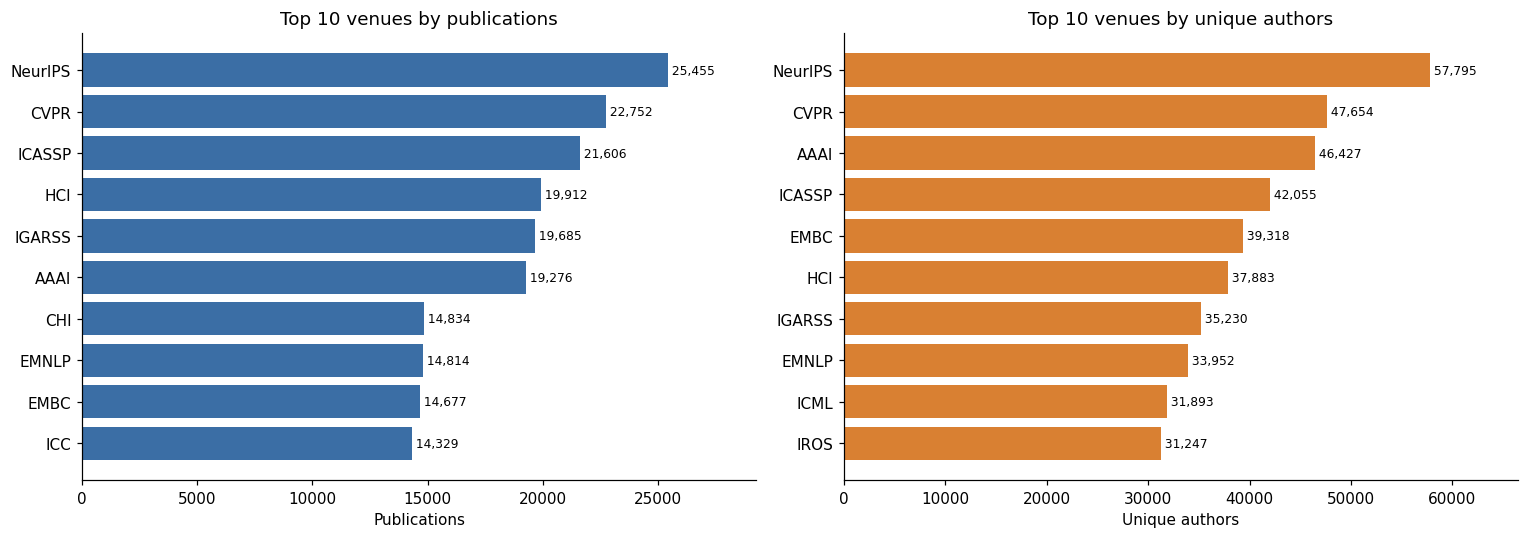

In [13]:
venue_popularity = popularity.venue_popularity(papers, authorship)
popularity.plot_top_venues(venue_popularity, 10)
display(popularity.top_by_publications(venue_popularity, 10))
display(popularity.top_by_unique_authors(venue_popularity, 10))

### Tren publikasi 2015-2025

venue,NeurIPS,CVPR,ICASSP,HCI,IGARSS,AAAI,CHI,EMNLP,EMBC,ICC
year,,,,,,,,,,
2015,440,733,1198,1713,1353,791,931,324,2004,1747
2016,594,836,1322,1470,1905,812,1134,271,1578,1080
2017,677,1064,1321,1404,1569,931,1068,417,1124,1398
2018,1009,1326,1395,1365,2208,1218,1213,672,1473,1271
2019,1518,1882,1735,1582,2273,1392,1316,788,1669,1237
2020,1949,1984,1863,2153,1641,1905,1365,1336,1462,1154
2021,2562,2175,1723,1834,2152,2061,1295,1336,1639,1116
2022,2849,2627,1864,2025,1936,1700,1142,1487,1105,1153
2023,3540,3051,2920,2238,2059,2076,1497,2242,1237,1408


,publications_2015,publications_2025,peak_year,peak_publications,years_without_data,growth_%
venue,,,,,,
NeurIPS,440,5823,2025,5823,0,1223.4
CVPR,733,3543,2025,3543,0,383.4
ICASSP,1198,3370,2025,3370,0,181.3
HCI,1713,2327,2025,2327,0,35.8
IGARSS,1353,0,2024,2589,1,NaN
AAAI,791,3508,2025,3508,0,343.5
CHI,931,2168,2025,2168,0,132.9
EMNLP,324,3491,2025,3491,0,977.5
EMBC,2004,0,2015,2004,1,NaN


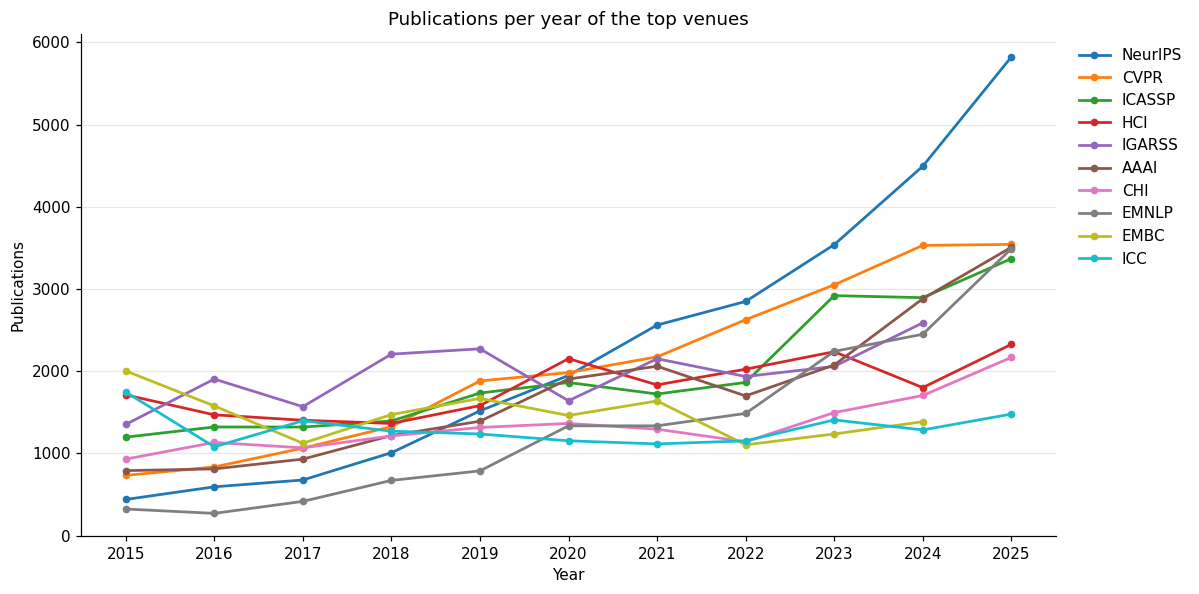

In [14]:
top_venues = popularity.top_by_publications(venue_popularity, 10).index.tolist()
popularity.plot_yearly_trend(papers, top_venues)
display(popularity.yearly_trend(papers, top_venues))
popularity.trend_summary(papers, top_venues)

### Perbandingan ranking
Membandingkan urutan conference berdasarkan jumlah publikasi dengan urutan berdasarkan jumlah author unik.

,publications,unique_authors,rank_publications,rank_authors,authors_per_publication,rank_shift
venue,,,,,,
NeurIPS,25455,57795,1,1,2.27,0
CVPR,22752,47654,2,2,2.09,0
ICASSP,21606,42055,3,4,1.95,-1
HCI,19912,37883,4,6,1.90,-2
IGARSS,19685,35230,5,7,1.79,-2
AAAI,19276,46427,6,3,2.41,3
CHI,14834,29904,7,12,2.02,-5
EMNLP,14814,33952,8,8,2.29,0
EMBC,14677,39318,9,5,2.68,4


,value
venues in both top 10,8.0000
spearman correlation (all venues),0.9872


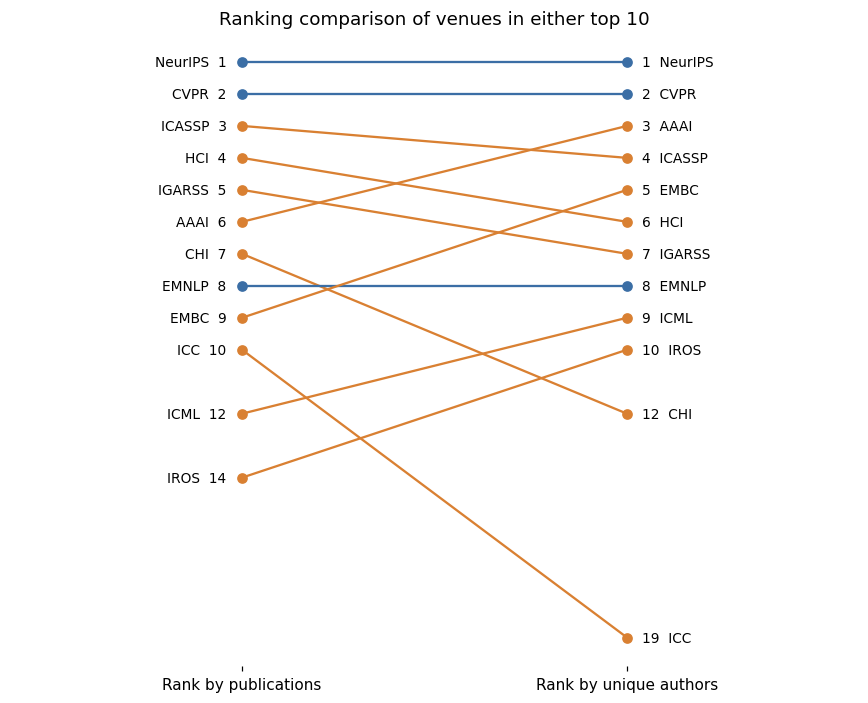

In [15]:
popularity.plot_ranking_comparison(venue_popularity, 10)
display(popularity.compare_rankings(venue_popularity, 10))
popularity.ranking_agreement(venue_popularity, 10).to_frame()

### Analisis popularitas conference
- Conference paling populer berdasarkan jumlah publikasi adalah NeurIPS (25.455 publikasi), diikuti CVPR (22.752) dan ICASSP (21.606). HCI di sini adalah HCI International.
- NeurIPS juga punya author unik terbanyak (57.795), dan CVPR tetap di posisi 2. Jadi untuk dua teratas jawabannya ya, tetapi tidak untuk semua: 8 dari 10 conference ada di kedua top 10, dengan urutan yang berbeda.
- ICC turun dari peringkat 10 ke 19 dan CHI dari 7 ke 12 jika diukur dengan author unik, artinya komunitas penulisnya lebih kecil dan lebih sering kembali. AAAI naik dari 6 ke 3 dan EMBC dari 9 ke 5, lalu ICML dan IROS masuk top 10 author.
- Secara keseluruhan kedua ukuran sangat sejalan (korelasi Spearman 0,987 pada 4.515 venue).
- Conference AI tumbuh paling cepat: NeurIPS dari 440 (2015) menjadi 5.823 (2025), EMNLP dari 324 menjadi 3.491, CVPR dari 733 menjadi 3.543, dan AAAI dari 791 menjadi 3.508.
- Conference di luar AI relatif stabil: ICC turun dari 1.747 menjadi 1.479 dan HCI bergerak di kisaran 1.400-2.300.
- Nilai 0 untuk IGARSS dan EMBC pada 2025 berarti prosidingnya belum diindeks DBLP, bukan konferensinya berhenti.

# Preparation
Mengubah tabel `authorship` menjadi transactional database. Setiap transaksi adalah himpunan conference, jadi satu conference hanya muncul sekali walaupun author punya banyak paper di sana.

### Author-based transaction
Satu transaksi per author, berisi semua conference tempat author itu publikasi selama 2015-2025. Contoh diambil dari transaksi dengan minimal 2 item supaya pola kemunculan bersama terlihat.

In [16]:
author_tx = prep.build_author_transactions(authorship)
prep.sample_transactions(author_tx, 10)

,author,items,n_items
0,Ketan Nehete,"(AIR, ICRA)",2
1,Shogo Okada,"(AAAI Spring Symposia, ACII, ACM Multimedia, APSIPA, ASCC, ASRU, CDC, EMBC, EUSIPCO, FG, HAI, HCI, HRI, ICASSP, ICME...",29
2,Mubashir Imran,"(DASFAA, ICADL, ICDE)",3
3,Bart Kofoed,"(AVSS, Digital Photography and Mobile Imaging)",2
4,Yi-Shyuan Chiang,"(AAAI, ACL, CHI, EACL, ECIR, EuroUSEC, IJCAI, NAACL-HLT, SIGIR)",9
5,Hristo Kostadinov,"(ACCT, ICCS, ICSOC, MIPRO)",4
6,Ifrah Pervaz,"(BIR Workshops, CLEF (Working Notes))",2
7,Keying Kuang,"(EMNLP, NeurIPS)",2
8,Nadzeya Kalbaska,"(DG.O, ENTER, HCI, ICEGOV)",4
9,Sirisha Rambhatla,"(AAAI, ACSSC, AMIA, Canadian AI, GlobalSIP, ICASSP, ICCV, ICLR, ICML, IJCAI, KDD, NeurIPS, WACV)",13


### Author-year-based transaction
Satu transaksi per pasangan author dan tahun, berisi conference tempat author itu publikasi pada tahun tersebut.

In [17]:
author_year_tx = prep.build_author_year_transactions(authorship)
prep.save_transactions(author_tx, author_year_tx)
prep.sample_transactions(author_year_tx, 10)

,author,year,items,n_items
0,Dimitri Lefebvre,2018,"(CoDIT, ETFA, ICINCO, SSCI)",4
1,Sofiane Achiche,2017,"(CCECE, GIIS)",2
2,Guobin Shen,2023,"(IJCAI, NeurIPS)",2
3,Seddik M. Djouadi,2021,"(ACC, CDC, ISGT)",3
4,Hanrui Wang 0002,2024,"(DAC, HPCA, ISCA)",3
5,Igor Isaev,2018,"(BICA, ICANN)",2
6,Xiaoxiao Sun 0001,2019,"(DASFAA, ICWS)",2
7,Bhawana Singh,2024,"(ICCCNT, VSS)",2
8,Ramya Raghavendra,2018,"(FUSION, IEEE BigData, MILCOM)",3
9,Javier Ruiz-Aranguren,2017,"(AGOP, IFSA-EUSFLAT)",2


### Statistik transaksi
Jumlah transaksi, jumlah item unik, dan distribusi jumlah item per transaksi untuk kedua representasi.

In [18]:
prep.compare_representations(author_tx, author_year_tx)

,author-based,author-year-based
transactions,1822238,4088191
unique items,4515,4515
total items,4859494,6504355
mean items per transaction,2.667,1.591
median items per transaction,1,1
max items per transaction,332,85
transactions with 1 item (%),58.39,71.02
transactions with >= 2 items (%),41.61,28.98
transactions with >= 3 items (%),25.6,12.79


author-based         author-year-based        
                      transactions share_%      transactions share_%
items_per_transaction                                               
1                          1063941   58.39           2903440   71.02
2                           291825   16.01            661764   16.19
3                           140849    7.73            253763    6.21
4                            84016    4.61            116991    2.86
5                            55317    3.04             60910    1.49
6                            38542    2.12             33862    0.83
7                            28332    1.55             19932    0.49
8                            21241    1.17             12426    0.30
9                            16268    0.89              7607    0.19
>=10                         81907    4.49             17496    0.43

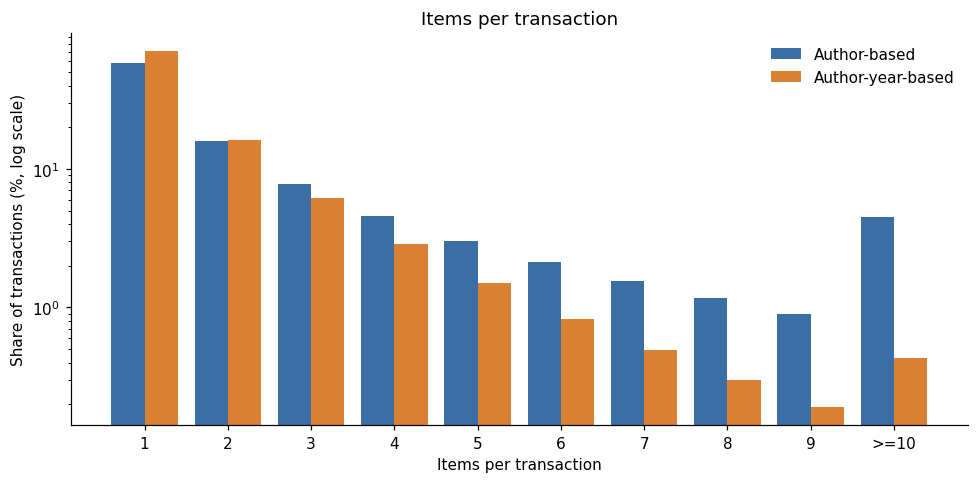

In [19]:
prep.plot_size_distribution(author_tx, author_year_tx)
pd.concat({"author-based": prep.size_distribution(author_tx), "author-year-based": prep.size_distribution(author_year_tx)}, axis=1)

### Perbedaan kedua representasi
- Author-based punya 1.822.238 transaksi dengan rata-rata 2,67 item, sedangkan author-year-based punya 4.088.191 transaksi dengan rata-rata 1,59 item. Keduanya memakai 4.515 item unik yang sama.
- Transaksi dengan 1 item tidak bisa membentuk pola kemunculan bersama. Porsinya 58,39% pada author-based dan 71,02% pada author-year-based, jadi author-year-based jauh lebih sparse.
- Transaksi terpanjang berisi 332 conference pada author-based dan 85 pada author-year-based.

Kelebihan dan keterbatasan untuk Frequent Pattern Mining:
- Author-based: transaksi lebih panjang sehingga lebih banyak pola yang lolos minimum support, cocok untuk melihat profil riset author. Keterbatasannya urutan waktu hilang (paper 2015 dan 2025 dianggap muncul bersama) dan author senior dengan ratusan conference menghasilkan sangat banyak kombinasi.
- Author-year-based: pola berarti dua conference diikuti pada tahun yang sama, sehingga bisa dibandingkan antar periode. Keterbatasannya support jauh lebih kecil, dan satu author aktif dihitung berulang kali (sekali per tahun) sehingga author produktif lebih berpengaruh.

# Modelling

### Apriori dan FP-Growth
Menjalankan kedua algoritma (implementasi sendiri di `frequent_pattern_mining.py`) pada author-based transaction dengan minimum support 0,1%, 0,5%, 1%, dan 2%. Setiap eksperimen diulang 3 kali agar waktu eksekusi yang dicatat adalah median.

,1-itemsets,2-itemsets,3-itemsets,4-itemsets,5-itemsets,6-itemsets,total,max_length
min_support,,,,,,,,
0.1%,572,393,348,159,37,3,1512,6
0.5%,66,21,1,0,0,0,88,3
1.0%,29,1,0,0,0,0,30,2
2.0%,6,0,0,0,0,0,6,1


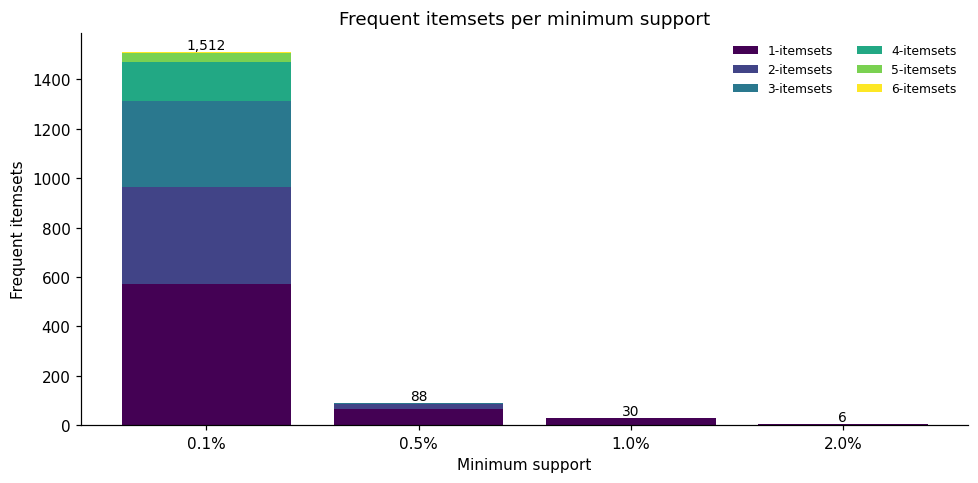

In [20]:
author_db = fpm.encode_transactions(author_tx["items"])
results = fpm.run_experiments(author_db, fpm.MIN_SUPPORTS, repeats=3)
itemset_counts = fpm.itemset_count_table(results, "Apriori")
fpm.plot_itemset_counts(itemset_counts)
itemset_counts

### Frequent 1-, 2-, dan 3-itemsets
Sepuluh itemset dengan support tertinggi untuk setiap panjang pada setiap minimum support. Sel kosong berarti tidak ada lagi itemset yang lolos.

In [21]:
for min_support in fpm.MIN_SUPPORTS:
    print(f"minimum support {min_support:.1%} (minimal {author_db.min_count(min_support):,} author)")
    display(fpm.itemsets_by_length(results[("Apriori", min_support)].itemsets, (1, 2, 3), 10))

minimum support 0.1% (minimal 1,823 author)


,1-itemsets,support 1,2-itemsets,support 2,3-itemsets,support 3
0,NeurIPS,3.172%,ICML + NeurIPS,1.016%,ICLR + ICML + NeurIPS,0.572%
1,CVPR,2.615%,ICLR + NeurIPS,0.980%,CVPR + ECCV + ICCV,0.465%
2,AAAI,2.548%,AAAI + NeurIPS,0.877%,CVPR + ICCV + NeurIPS,0.461%
3,ICASSP,2.308%,CVPR + NeurIPS,0.858%,AAAI + ICML + NeurIPS,0.416%
4,EMBC,2.158%,CVPR + ICCV,0.847%,AAAI + ICLR + NeurIPS,0.405%
5,HCI,2.079%,ACL + EMNLP,0.799%,AAAI + CVPR + NeurIPS,0.401%
6,IGARSS,1.933%,CVPR + ECCV,0.755%,CVPR + ECCV + NeurIPS,0.399%
7,EMNLP,1.863%,ICLR + ICML,0.711%,CVPR + ICLR + NeurIPS,0.393%
8,ICML,1.750%,AAAI + CVPR,0.668%,AAAI + CVPR + ICCV,0.355%
9,IROS,1.715%,ICRA + IROS,0.651%,CVPR + ICML + NeurIPS,0.344%


minimum support 0.5% (minimal 9,112 author)


,1-itemsets,support 1,2-itemsets,support 2,3-itemsets,support 3
0,NeurIPS,3.172%,ICML + NeurIPS,1.016%,ICLR + ICML + NeurIPS,0.572%
1,CVPR,2.615%,ICLR + NeurIPS,0.980%,,
2,AAAI,2.548%,AAAI + NeurIPS,0.877%,,
3,ICASSP,2.308%,CVPR + NeurIPS,0.858%,,
4,EMBC,2.158%,CVPR + ICCV,0.847%,,
5,HCI,2.079%,ACL + EMNLP,0.799%,,
6,IGARSS,1.933%,CVPR + ECCV,0.755%,,
7,EMNLP,1.863%,ICLR + ICML,0.711%,,
8,ICML,1.750%,AAAI + CVPR,0.668%,,
9,IROS,1.715%,ICRA + IROS,0.651%,,


minimum support 1.0% (minimal 18,223 author)


,1-itemsets,support 1,2-itemsets,support 2,3-itemsets,support 3
0,NeurIPS,3.172%,ICML + NeurIPS,1.016%,,
1,CVPR,2.615%,,,,
2,AAAI,2.548%,,,,
3,ICASSP,2.308%,,,,
4,EMBC,2.158%,,,,
5,HCI,2.079%,,,,
6,IGARSS,1.933%,,,,
7,EMNLP,1.863%,,,,
8,ICML,1.750%,,,,
9,IROS,1.715%,,,,


minimum support 2.0% (minimal 36,445 author)


,1-itemsets,support 1,2-itemsets,support 2,3-itemsets,support 3
0,NeurIPS,3.172%,,,,
1,CVPR,2.615%,,,,
2,AAAI,2.548%,,,,
3,ICASSP,2.308%,,,,
4,EMBC,2.158%,,,,
5,HCI,2.079%,,,,


### Top 10 frequent itemsets

In [22]:
for min_support in fpm.MIN_SUPPORTS:
    print(f"minimum support {min_support:.1%}")
    display(fpm.top_itemsets(results[("Apriori", min_support)].itemsets, 10))

minimum support 0.1%


,itemset,length,support_count,support
0,"(NeurIPS,)",1,57795,0.0317
1,"(CVPR,)",1,47654,0.0262
2,"(AAAI,)",1,46427,0.0255
3,"(ICASSP,)",1,42055,0.0231
4,"(EMBC,)",1,39318,0.0216
5,"(HCI,)",1,37883,0.0208
6,"(IGARSS,)",1,35230,0.0193
7,"(EMNLP,)",1,33952,0.0186
8,"(ICML,)",1,31893,0.0175
9,"(IROS,)",1,31247,0.0171


minimum support 0.5%


,itemset,length,support_count,support
0,"(NeurIPS,)",1,57795,0.0317
1,"(CVPR,)",1,47654,0.0262
2,"(AAAI,)",1,46427,0.0255
3,"(ICASSP,)",1,42055,0.0231
4,"(EMBC,)",1,39318,0.0216
5,"(HCI,)",1,37883,0.0208
6,"(IGARSS,)",1,35230,0.0193
7,"(EMNLP,)",1,33952,0.0186
8,"(ICML,)",1,31893,0.0175
9,"(IROS,)",1,31247,0.0171


minimum support 1.0%


,itemset,length,support_count,support
0,"(NeurIPS,)",1,57795,0.0317
1,"(CVPR,)",1,47654,0.0262
2,"(AAAI,)",1,46427,0.0255
3,"(ICASSP,)",1,42055,0.0231
4,"(EMBC,)",1,39318,0.0216
5,"(HCI,)",1,37883,0.0208
6,"(IGARSS,)",1,35230,0.0193
7,"(EMNLP,)",1,33952,0.0186
8,"(ICML,)",1,31893,0.0175
9,"(IROS,)",1,31247,0.0171


minimum support 2.0%


,itemset,length,support_count,support
0,"(NeurIPS,)",1,57795,0.0317
1,"(CVPR,)",1,47654,0.0262
2,"(AAAI,)",1,46427,0.0255
3,"(ICASSP,)",1,42055,0.0231
4,"(EMBC,)",1,39318,0.0216
5,"(HCI,)",1,37883,0.0208


### Kombinasi conference
Itemset dengan panjang minimal 2 dan minimal 3 yang paling sering muncul bersama, dari eksperimen minimum support 0,1%.

,itemset,length,support_count,support
0,"(ICML, NeurIPS)",2,18505,0.0102
1,"(ICLR, NeurIPS)",2,17855,0.0098
2,"(AAAI, NeurIPS)",2,15974,0.0088
3,"(CVPR, NeurIPS)",2,15641,0.0086
4,"(CVPR, ICCV)",2,15437,0.0085
5,"(ACL, EMNLP)",2,14558,0.0080
6,"(CVPR, ECCV)",2,13753,0.0075
7,"(ICLR, ICML)",2,12948,0.0071
8,"(AAAI, CVPR)",2,12169,0.0067
9,"(ICRA, IROS)",2,11860,0.0065


,itemset,length,support_count,support
0,"(ICLR, ICML, NeurIPS)",3,10415,0.0057
1,"(CVPR, ECCV, ICCV)",3,8473,0.0046
2,"(CVPR, ICCV, NeurIPS)",3,8407,0.0046
3,"(AAAI, ICML, NeurIPS)",3,7589,0.0042
4,"(AAAI, ICLR, NeurIPS)",3,7373,0.0040
5,"(AAAI, CVPR, NeurIPS)",3,7304,0.0040
6,"(CVPR, ECCV, NeurIPS)",3,7275,0.0040
7,"(CVPR, ICLR, NeurIPS)",3,7160,0.0039
8,"(AAAI, CVPR, ICCV)",3,6477,0.0036
9,"(CVPR, ICML, NeurIPS)",3,6261,0.0034


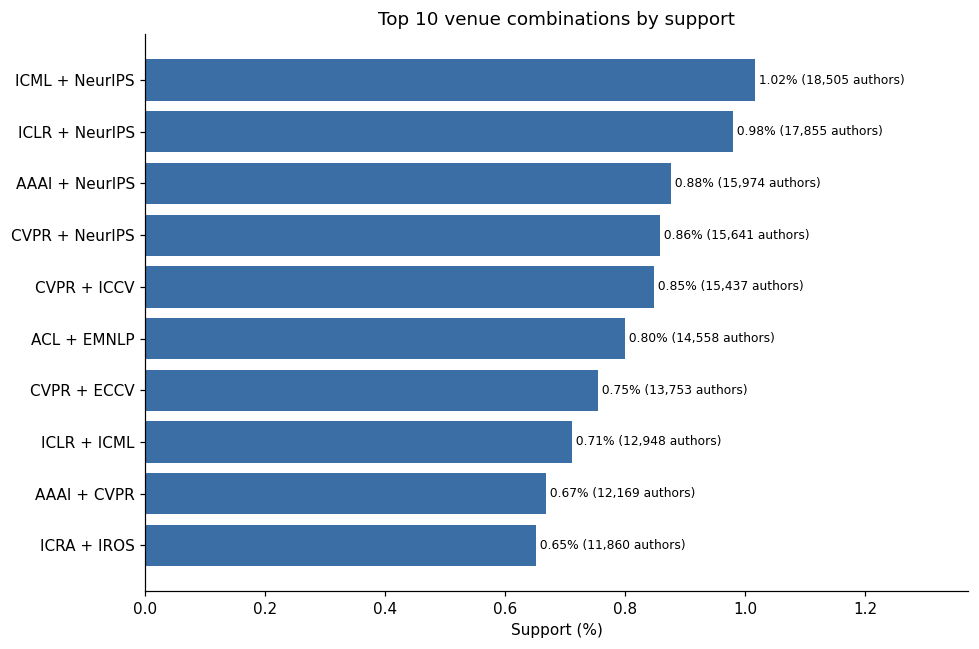

In [23]:
lowest_support = min(fpm.MIN_SUPPORTS)
all_itemsets = results[("Apriori", lowest_support)].itemsets
fpm.plot_top_itemsets(all_itemsets, 10, min_length=2)
display(fpm.top_itemsets(all_itemsets, 10, min_length=2))
fpm.top_itemsets(all_itemsets, 10, min_length=3)

### Interpretasi frequent patterns
- Menurunkan minimum support menambah itemset dengan sangat cepat: 6 itemset pada 2%, 30 pada 1%, 88 pada 0,5%, dan 1.512 pada 0,1%. Panjang maksimum itemset juga naik dari 1 menjadi 2, 3, lalu 6.
- Pada 2% (minimal 36.445 author) hanya ada enam 1-itemset: NeurIPS, CVPR, AAAI, ICASSP, EMBC, dan HCI. Belum ada kombinasi, karena conference terbesar pun hanya diikuti 3,17% author.
- Kombinasi pertama muncul pada 1%: ICML + NeurIPS (18.505 author, support 1,02%). Kombinasi tiga conference pertama muncul pada 0,5%: ICLR + ICML + NeurIPS (10.415 author).
- Top 10 frequent itemsets pada semua minimum support selalu berupa 1-itemset, karena support sebuah kombinasi tidak mungkin lebih besar dari support anggotanya.
- Kombinasi yang paling sering muncul bersama membentuk kelompok bidang: machine learning (ICML, ICLR, NeurIPS, AAAI), computer vision (CVPR, ICCV, ECCV), NLP (ACL, EMNLP), robotika (ICRA, IROS), dan jaringan (GLOBECOM, ICC).
- Pada 0,1% ada tiga 6-itemset, semuanya gabungan vision dan machine learning, contohnya AAAI + CVPR + ECCV + ICCV + ICLR + NeurIPS (2.007 author). Ini menunjukkan ada kelompok author yang publikasi di hampir semua conference AI besar.

### Association rules
Membangkitkan rule dari frequent itemsets dengan minimum confidence 50%, lalu menghitung support, confidence, dan lift setiap rule.

,rules,max_lift,median_lift,max_confidence,max_support
min_support,,,,,
0.1%,1388,172.3489,35.5554,0.9603,0.0102
0.5%,7,33.3280,22.2943,0.8044,0.0102
1.0%,1,18.2940,18.2940,0.5802,0.0102
2.0%,0,NaN,NaN,NaN,NaN


,antecedent,consequent,support,confidence,lift,support_count,antecedent_support,consequent_support
0,"(ACM Multimedia, ECCV, NeurIPS)","(AAAI, CVPR, ICCV)",0.0010,0.6126,172.3489,1828,0.0016,0.0036
1,"(CVPR, ECCV, ICML)","(ICCV, ICLR, NeurIPS)",0.0010,0.5027,171.9024,1851,0.0020,0.0029
2,"(CVPR, ICCV, ICML, NeurIPS)","(ECCV, ICLR)",0.0010,0.5143,159.4953,1851,0.0020,0.0032
3,"(CVPR, ECCV, ICML, NeurIPS)","(ICCV, ICLR)",0.0010,0.5916,157.4366,1851,0.0017,0.0038
4,"(ECCV, ICCV, ICML)","(CVPR, ICLR, NeurIPS)",0.0010,0.6143,156.3505,1851,0.0017,0.0039
...,...,...,...,...,...,...,...,...
1383,"(EMNLP, WWW)","(NeurIPS,)",0.0011,0.5050,15.9215,2081,0.0023,0.0317
1384,"(CVPR, ICRA)","(NeurIPS,)",0.0013,0.5040,15.8897,2414,0.0026,0.0317
1385,"(CIKM, EMNLP)","(NeurIPS,)",0.0011,0.5024,15.8407,2083,0.0023,0.0317
1386,"(BMVC, CVPR)","(NeurIPS,)",0.0012,0.5022,15.8349,2256,0.0025,0.0317


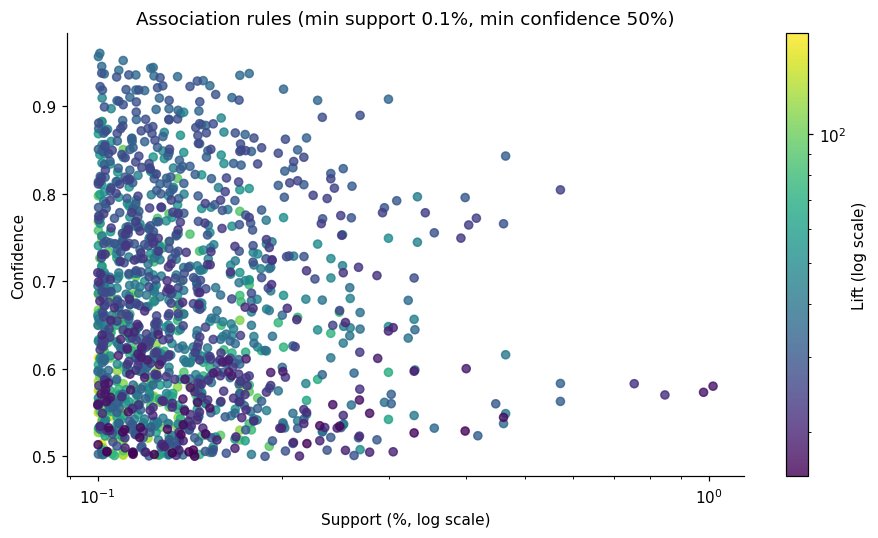

In [24]:
rules = arm.generate_rules(results, arm.MIN_CONFIDENCE)
display(arm.rule_count_table(rules, "Apriori"))
all_rules = rules[("Apriori", lowest_support)]
arm.plot_rules(all_rules, f"Association rules (min support {lowest_support:.1%}, min confidence {arm.MIN_CONFIDENCE:.0%})")
all_rules

### Top 10 rules
Sepuluh rule dengan lift tertinggi, lalu support tertinggi, lalu confidence tertinggi.

In [25]:
display(arm.format_rules(arm.top_rules(all_rules, 10, by="lift")))
display(arm.format_rules(arm.top_rules(all_rules, 10, by="support")))
arm.format_rules(arm.top_rules(all_rules, 10, by="confidence"))

,rule,support,confidence,lift,support_count
0,"ACM Multimedia, ECCV, NeurIPS -> AAAI, CVPR, ICCV",0.0010,0.613,172.35,1828
1,"CVPR, ECCV, ICML -> ICCV, ICLR, NeurIPS",0.0010,0.503,171.90,1851
2,"CVPR, ICCV, ICML, NeurIPS -> ECCV, ICLR",0.0010,0.514,159.50,1851
3,"CVPR, ECCV, ICML, NeurIPS -> ICCV, ICLR",0.0010,0.592,157.44,1851
4,"ECCV, ICCV, ICML -> CVPR, ICLR, NeurIPS",0.0010,0.614,156.35,1851
5,"ICLR, NAACL-HLT -> ACL, EMNLP, NeurIPS",0.0010,0.504,152.52,1918
6,"ACM Multimedia, CVPR, ICCV, NeurIPS -> AAAI, ECCV",0.0010,0.575,147.70,1828
7,"EMNLP, NAACL-HLT, NeurIPS -> ACL, ICLR",0.0010,0.546,146.20,1918
8,"ACM Multimedia, CVPR, ECCV, NeurIPS -> AAAI, ICCV",0.0010,0.685,145.55,1828
9,"CVPR, ECCV, ICML -> ICCV, ICLR",0.0011,0.536,142.68,1974


,rule,support,confidence,lift,support_count
0,ICML -> NeurIPS,0.0102,0.580,18.29,18505
1,ICLR -> NeurIPS,0.0098,0.573,18.07,17855
2,ICCV -> CVPR,0.0085,0.570,21.80,15437
3,ECCV -> CVPR,0.0076,0.583,22.29,13753
4,"ICLR, ICML -> NeurIPS",0.0057,0.804,25.36,10415
5,"ICLR, NeurIPS -> ICML",0.0057,0.583,33.33,10415
6,"ICML, NeurIPS -> ICLR",0.0057,0.563,32.93,10415
7,"ECCV, ICCV -> CVPR",0.0046,0.843,32.24,8473
8,"CVPR, ECCV -> ICCV",0.0046,0.616,41.47,8473
9,"CVPR, ICCV -> ECCV",0.0046,0.549,42.40,8473


,rule,support,confidence,lift,support_count
0,"ECCV, ICCV, NeurIPS, WACV -> CVPR",0.0010,0.960,36.72,1838
1,"AAAI, ACM Multimedia, ECCV, ICCV, NeurIPS -> CVPR",0.0010,0.957,36.58,1828
2,"AAAI, ECCV, ICCV, ICLR, NeurIPS -> CVPR",0.0011,0.952,36.41,2007
3,"ECCV, ICCV, ICLR, ICML, NeurIPS -> CVPR",0.0010,0.945,36.15,1851
4,"ACM Multimedia, ECCV, ICCV, NeurIPS -> CVPR",0.0012,0.944,36.10,2247
5,"AAAI, ECCV, ICCV, ICLR -> CVPR",0.0012,0.943,36.07,2226
6,"ECCV, ICCV, ICLR, ICML -> CVPR",0.0011,0.941,35.98,1974
7,"CVPR, ECCV, ICCV, ICLR, ICML -> NeurIPS",0.0010,0.938,29.56,1851
8,"AAAI, ECCV, ICCV, NeurIPS -> CVPR",0.0018,0.937,35.84,3226
9,"AAAI, ECCV, ICCV, ICML -> CVPR",0.0010,0.937,35.82,1869


### Rule satu ke satu
Rule dengan satu conference di kiri dan satu di kanan paling mudah dibaca sebagai hubungan langsung antara dua conference.

In [26]:
one_to_one = all_rules[(all_rules["antecedent"].str.len() == 1) & (all_rules["consequent"].str.len() == 1)]
arm.format_rules(one_to_one)

,rule,support,confidence,lift,support_count
0,ECOC -> OFC,0.0025,0.665,80.14,4530
1,ASRU -> INTERSPEECH,0.0011,0.727,74.20,1959
2,CoRL -> ICRA,0.0011,0.581,37.12,2084
3,EACL -> ACL,0.0016,0.596,36.60,2924
4,SPAWC -> ICC,0.0011,0.530,36.25,1926
5,Conference on Designing Interactive Systems -> CHI,0.0017,0.558,34.00,3167
6,SPAWC -> GLOBECOM,0.0010,0.503,33.81,1828
7,EACL -> EMNLP,0.0016,0.612,32.86,3004
8,NAACL-HLT -> ACL,0.0042,0.524,32.15,7631
9,IJCNLP -> ACL,0.0010,0.505,30.99,1886


### Support dan lift
Mengecek apakah rule dengan support tinggi juga punya lift tinggi.

,support,confidence,lift
support,1.0000,-0.0492,-0.2099
confidence,-0.0492,1.0000,-0.0715
lift,-0.2099,-0.0715,1.0000


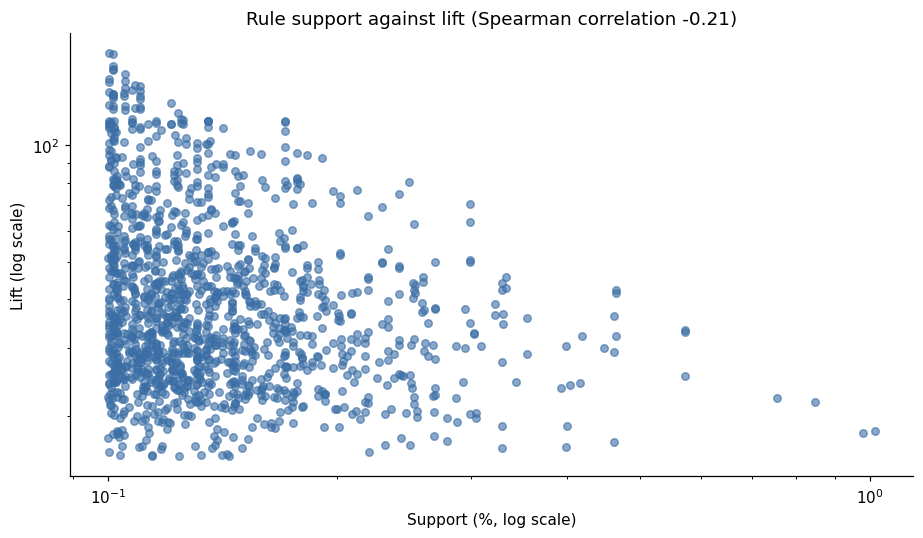

In [27]:
arm.plot_support_vs_lift(all_rules)
all_rules[["support", "confidence", "lift"]].corr(method="spearman")

### Interpretasi association rules
Arti ketiga ukuran untuk rule A -> B:
- support: porsi author yang publikasi di A dan B sekaligus. Mengukur seberapa umum polanya.
- confidence: dari author yang publikasi di A, berapa porsi yang juga publikasi di B. Mengukur seberapa bisa diandalkan rule itu, tetapi bisa tinggi hanya karena B memang conference besar.
- lift: confidence dibagi support B. Mengukur berapa kali lebih sering A dan B muncul bersama dibanding jika keduanya tidak berhubungan. Lift 1 berarti tidak ada hubungan.

Hasil:
- Jumlah rule: 1.388 pada minimum support 0,1%, 7 pada 0,5%, 1 pada 1% (ICML -> NeurIPS), dan 0 pada 2% karena belum ada kombinasi yang frequent.
- Lift tertinggi adalah ACM Multimedia, ECCV, NeurIPS -> AAAI, CVPR, ICCV (lift 172,35, confidence 61,3%, 1.828 author). Sepuluh rule dengan lift tertinggi semuanya berisi gabungan conference vision, NLP, dan machine learning, dengan support di sekitar batas 0,1%.
- Hubungan satu ke satu yang paling menarik adalah conference kecil yang mengarah ke conference utama bidangnya: ECOC -> OFC (lift 80,14, confidence 66,5%), ASRU -> INTERSPEECH (74,20), CoRL -> ICRA (37,12), EACL -> ACL (36,60), dan AISTATS -> ICML (30,45).
- Support tinggi tidak selalu menghasilkan lift tinggi. Korelasi Spearman antara support dan lift adalah -0,21. Rule dengan support terbesar, ICML -> NeurIPS (1,02%), hanya punya lift 18,29, sedangkan rule dengan lift di atas 150 punya support sekitar 0,10%.
- Penyebabnya, conference besar sudah sering muncul dengan sendirinya sehingga pembagi pada lift besar. HCI, IGARSS, dan EMBC termasuk enam conference dengan support tertinggi tetapi tidak muncul di satu rule pun.
- Rule hampir selalu mengarah dari conference yang lebih kecil ke yang lebih besar: NeurIPS menjadi consequent pada 241 rule dan CVPR pada 160 rule, tetapi keduanya tidak pernah menjadi antecedent tunggal. Author conference kecil cenderung juga publikasi di conference utama, tetapi tidak sebaliknya.
- Pola publikasi mengikuti bidang riset: vision (ECCV, ICCV, BMVC, ACCV, 3DV -> CVPR), machine learning (ICML, ICLR, AISTATS, UAI -> NeurIPS), NLP (NAACL-HLT, EACL, IJCNLP -> ACL dan EMNLP), komunikasi (SPAWC -> ICC dan GLOBECOM), dan HCI (Designing Interactive Systems -> CHI).

### Temporal association mining
Menjalankan FP-Growth pada author-year-based transaction untuk setiap periode dengan minimum support 0,1% dan minimum confidence 50%. FP-Growth dan Apriori memberi hasil yang sama (lihat Evaluation), jadi cukup satu algoritma.

,transactions,frequent_itemsets,1-itemsets,2-itemsets,3+-itemsets,association_rules
period,,,,,,
2015-2017,923118,356,345,11,0,1
2018-2020,1081603,327,305,22,0,0
2021-2023,1196827,359,311,45,3,3
2024-2025,886643,489,294,129,66,60


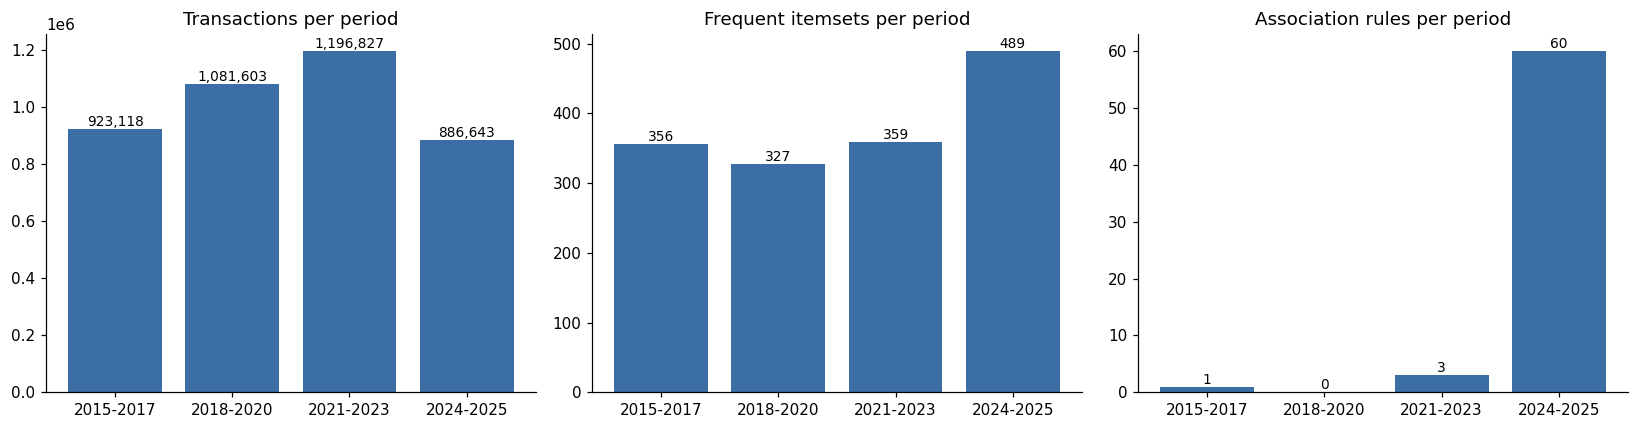

In [28]:
TEMPORAL_MIN_SUPPORT = 0.001
period_tx = prep.split_by_period(author_year_tx)
period_results, period_rules = temporal.mine_periods(period_tx, TEMPORAL_MIN_SUPPORT, arm.MIN_CONFIDENCE)
temporal.plot_period_summary(period_results, period_rules)
temporal.period_summary(period_results, period_rules)

### Frequent itemsets dan rules per periode

In [29]:
for period in period_results:
    print(period)
    display(fpm.top_itemsets(period_results[period].itemsets, 10, min_length=2))
    display(arm.format_rules(arm.top_rules(period_rules[period], 10)))

2015-2017


,itemset,length,support_count,support
0,"(GLOBECOM, ICC)",2,2957,0.0032
1,"(ACC, CDC)",2,1880,0.0020
2,"(ICRA, IROS)",2,1780,0.0019
3,"(ECOC, OFC)",2,1721,0.0019
4,"(GLOBECOM, VTC Fall)",2,1544,0.0017
5,"(ICC, VTC Fall)",2,1542,0.0017
6,"(AAAI, IJCAI)",2,1450,0.0016
7,"(ICASSP, INTERSPEECH)",2,1296,0.0014
8,"(CVPR, ICCV)",2,1226,0.0013
9,"(ICC, WCNC)",2,956,0.0010


,rule,support,confidence,lift,support_count
0,ECOC -> OFC,0.0019,0.516,59.83,1721


2018-2020


,itemset,length,support_count,support
0,"(CVPR, ECCV)",2,2986,0.0028
1,"(GLOBECOM, ICC)",2,2726,0.0025
2,"(ICML, NeurIPS)",2,2611,0.0024
3,"(ICRA, IROS)",2,2215,0.0020
4,"(AAAI, IJCAI)",2,2184,0.0020
5,"(ACL, EMNLP)",2,2174,0.0020
6,"(ICASSP, INTERSPEECH)",2,1947,0.0018
7,"(ICLR, NeurIPS)",2,1923,0.0018
8,"(CVPR, NeurIPS)",2,1794,0.0017
9,"(AAAI, CVPR)",2,1779,0.0016


,rule,support,confidence,lift,support_count


... (2 outputs left out)

,rule,support,confidence,lift,support_count
0,"ICCV, NeurIPS -> CVPR",0.0014,0.580,23.87,1652
1,"ICLR, ICML -> NeurIPS",0.0016,0.635,23.17,1950
2,"CVPR, ICLR -> NeurIPS",0.0011,0.548,20.00,1270


2024-2025


,itemset,length,support_count,support
0,"(ICLR, NeurIPS)",2,9266,0.0105
1,"(ICML, NeurIPS)",2,8746,0.0099
2,"(CVPR, NeurIPS)",2,7381,0.0083
3,"(ACL, EMNLP)",2,7153,0.0081
4,"(ICLR, ICML)",2,6498,0.0073
5,"(AAAI, NeurIPS)",2,6289,0.0071
6,"(EMNLP, NeurIPS)",2,5098,0.0057
7,"(ACL, NeurIPS)",2,5053,0.0057
8,"(CVPR, ICCV)",2,4678,0.0053
9,"(AAAI, CVPR)",2,4631,0.0052


,rule,support,confidence,lift,support_count
0,"EMNLP, NAACL-HLT, NeurIPS -> ACL",0.0010,0.724,28.95,901
1,"ACL, NAACL-HLT, NeurIPS -> EMNLP",0.0010,0.708,25.50,901
2,"EMNLP, ICLR, NeurIPS -> ACL",0.0014,0.594,23.75,1223
3,"ICLR, NAACL-HLT -> ACL",0.0013,0.583,23.33,1107
4,"NAACL-HLT, NeurIPS -> ACL",0.0014,0.572,22.87,1273
5,"EMNLP, NAACL-HLT -> ACL",0.0023,0.568,22.73,2055
6,"COLING, EMNLP -> ACL",0.0016,0.564,22.57,1463
7,"EMNLP, ICML, NeurIPS -> ACL",0.0011,0.562,22.50,972
8,"ACL, ICML, NeurIPS -> ICLR",0.0012,0.639,22.33,1080
9,"EMNLP, ICML, NeurIPS -> ICLR",0.0012,0.615,21.48,1062


### Perbandingan antarperiode
Menandai setiap rule dan setiap kombinasi conference sebagai persistent (ada di semua periode), emerging (tidak ada di periode pertama, ada di periode terakhir), vanished (sebaliknya), atau temporary. Angka pada tabel rule adalah lift, dan pada tabel kombinasi adalah support dalam persen.

In [30]:
rule_changes = temporal.rule_persistence(period_rules, "lift")
display(temporal.pattern_counts(rule_changes).to_frame())
rule_changes.head(15)

,rules
pattern,
emerging,60
vanished,1


,2015-2017,2018-2020,2021-2023,2024-2025,periods_present,pattern
rule,,,,,,
"ICCV, NeurIPS -> CVPR",NaN,NaN,23.8691,15.7154,2,emerging
"ICLR, ICML -> NeurIPS",NaN,NaN,23.1726,12.0859,2,emerging
"CVPR, ICLR -> NeurIPS",NaN,NaN,19.9966,11.7565,2,emerging
"EMNLP, NAACL-HLT, NeurIPS -> ACL",NaN,NaN,NaN,28.9466,1,emerging
"ACL, NAACL-HLT, NeurIPS -> EMNLP",NaN,NaN,NaN,25.5038,1,emerging
"EMNLP, ICLR, NeurIPS -> ACL",NaN,NaN,NaN,23.7466,1,emerging
"ICLR, NAACL-HLT -> ACL",NaN,NaN,NaN,23.3288,1,emerging
"NAACL-HLT, NeurIPS -> ACL",NaN,NaN,NaN,22.8742,1,emerging
"EMNLP, NAACL-HLT -> ACL",NaN,NaN,NaN,22.7314,1,emerging


,itemsets
pattern,
emerging,185
persistent,8
temporary,2
vanished,1


,2015-2017,2018-2020,2021-2023,2024-2025,periods_present,pattern
itemset,,,,,,
ICML + NeurIPS,0.1010,0.2414,0.4538,0.9864,4,persistent
CVPR + ICCV,0.1328,0.1287,0.4224,0.5276,4,persistent
ICRA + IROS,0.1928,0.2048,0.2210,0.3228,4,persistent
AAAI + IJCAI,0.1571,0.2019,0.1887,0.3108,4,persistent
GLOBECOM + ICC,0.3203,0.2520,0.2676,0.2493,4,persistent
ICASSP + INTERSPEECH,0.1404,0.1800,0.2546,0.2397,4,persistent
GLOBECOM + VTC Fall,0.1673,0.1120,0.1248,0.1424,4,persistent
ICC + VTC Fall,0.1670,0.1105,0.1034,0.1337,4,persistent
ECOC + OFC,0.1864,0.1440,NaN,0.1331,3,temporary


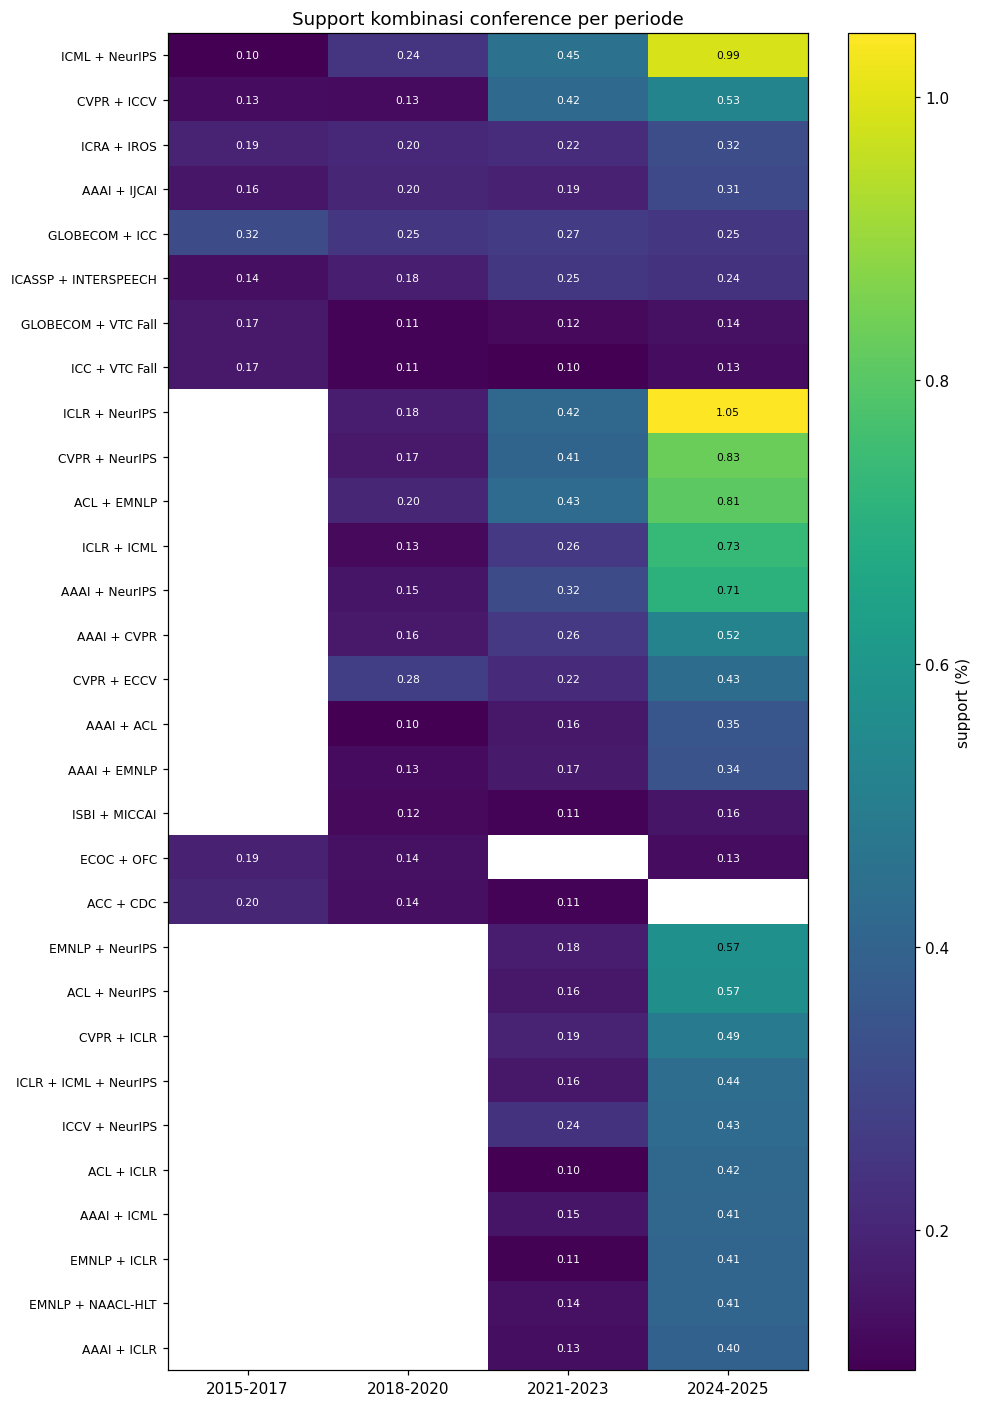

In [31]:
itemset_changes = temporal.itemset_support_over_time(period_results)
temporal.plot_period_heatmap(itemset_changes, 30, "support (%)", "Support kombinasi conference per periode")
display(itemset_changes["pattern"].value_counts().to_frame("itemsets"))
itemset_changes[itemset_changes["pattern"] != "emerging"]

### Interpretasi temporal
- Jumlah pola naik tajam di periode terakhir: kombinasi conference yang frequent naik dari 11 (2015-2017) menjadi 22, 48, lalu 195 (2024-2025), dan rule dari 1, 0, 3, menjadi 60.
- Pola yang bertahan di semua periode ada 8 kombinasi dan semuanya pasangan dalam satu bidang: ICML + NeurIPS, CVPR + ICCV, ICRA + IROS, AAAI + IJCAI, GLOBECOM + ICC, ICASSP + INTERSPEECH, GLOBECOM + VTC Fall, dan ICC + VTC Fall.
- Pola yang menguat: support ICML + NeurIPS naik dari 0,10% menjadi 0,99% dan CVPR + ICCV dari 0,13% menjadi 0,53%. Pola yang melemah: GLOBECOM + ICC turun dari 0,32% menjadi 0,25%.
- Pola yang berubah: pada 2015-2017 kombinasi teratas adalah jaringan dan kontrol (GLOBECOM + ICC, ACC + CDC), sedangkan pada 2024-2025 sepuluh kombinasi teratas semuanya conference AI (ICLR + NeurIPS di posisi pertama dengan 1,05%).
- Tidak ada rule yang bertahan di semua periode. ECOC -> OFC hanya lolos di 2015-2017. Tiga rule muncul di 2021-2023 (contoh ICLR, ICML -> NeurIPS) dan tetap ada di 2024-2025 dengan lift yang turun (23,17 menjadi 12,09) karena NeurIPS makin besar.
- 60 rule baru di 2024-2025 didominasi NLP dan machine learning, contohnya EMNLP, NAACL-HLT, NeurIPS -> ACL (lift 28,95). Ini menunjukkan author NLP kini juga publikasi di conference machine learning umum.
- Kemungkinan perubahan tren: riset bergeser ke AI, dan author AI makin sering publikasi di banyak conference besar dalam tahun yang sama, sehingga batas antar bidang vision, NLP, dan machine learning makin kabur.
- ACC + CDC tercatat vanished di 2024-2025. Ini perlu dibaca hati-hati karena sebagian prosiding 2025 belum masuk DBLP.

# Evaluation

### Perbandingan performa
Membandingkan Apriori dan FP-Growth pada author-based transaction yang sama dan minimum support yang sama: jumlah frequent itemsets, jumlah association rules, dan median waktu eksekusi.

frequent_itemsets  association_rules  \
min_support algorithm                                         
0.1%        Apriori                 1512               1388   
            FP-Growth               1512               1388   
0.5%        Apriori                   88                  7   
            FP-Growth                 88                  7   
1.0%        Apriori                   30                  1   
            FP-Growth                 30                  1   
2.0%        Apriori                    6                  0   
            FP-Growth                  6                  0   

                       max_itemset_length  runtime_s  
min_support algorithm                                 
0.1%        Apriori                     6      8.738  
            FP-Growth                   6     21.702  
0.5%        Apriori                     3      2.359  
            FP-Growth                   3      5.937  
1.0%        Apriori                     2      1.794  
            FP-Growth                   2      3.096  
2.0%        Apriori                     1      1.283  
            FP-Growth                   1      1.713

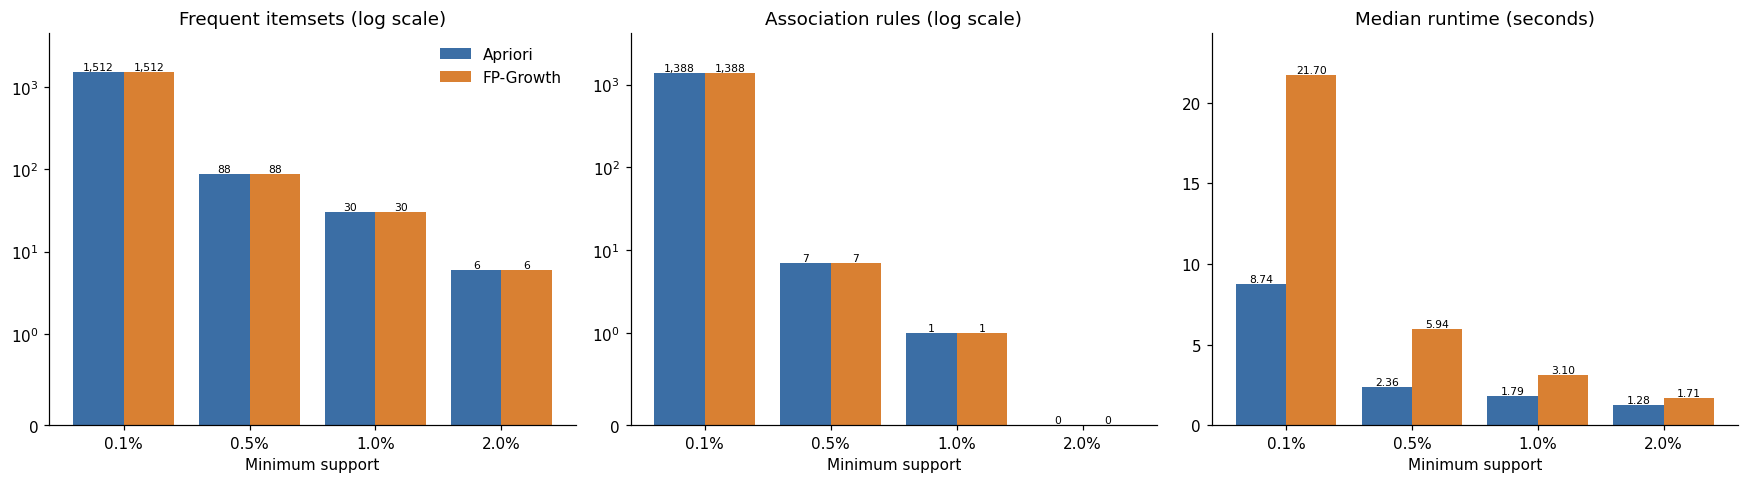

In [32]:
evaluation.plot_performance(results, rules)
evaluation.performance_table(results, rules)

### Kesamaan hasil
Mengecek apakah kedua algoritma menghasilkan itemset, support count, dan rule yang persis sama.

In [33]:
evaluation.compare_results(results, rules)

,itemsets_Apriori,itemsets_FP-Growth,itemsets_in_both,same_itemsets,same_support_counts,same_rules
min_support,,,,,,
0.1%,1512,1512,1512,True,True,True
0.5%,88,88,88,True,True,True
1.0%,30,30,30,True,True,True
2.0%,6,6,6,True,True,True


### Uji dengan mlxtend
Menguji implementasi sendiri terhadap FP-Growth dari library mlxtend pada minimum support 0,1%, yaitu eksperimen dengan itemset terbanyak.

In [34]:
pd.DataFrame([evaluation.crosscheck_with_mlxtend(author_db, results[(algorithm, lowest_support)]) for algorithm in fpm.ALGORITHMS])

,min_support,our itemsets,mlxtend itemsets,same itemsets,same support counts
Apriori vs mlxtend,0.1%,1512,1512,True,True
FP-Growth vs mlxtend,0.1%,1512,1512,True,True


### Analisis performa
- Pengaruh minimum support: makin kecil minimum support, makin banyak itemset dan rule yang harus ditemukan (6 itemset dan 0 rule pada 2%, 1.512 itemset dan 1.388 rule pada 0,1%), sehingga waktu eksekusi kedua algoritma naik.
- Kedua algoritma menghasilkan frequent itemsets, support count, dan association rules yang persis sama pada semua minimum support. Hasilnya juga sama dengan mlxtend.
- Pada dataset ini Apriori lebih cepat daripada FP-Growth di semua minimum support (lihat kolom `runtime_s`). Selisihnya paling besar pada 0,1% dan paling kecil pada 2%, saat hanya 1-itemset yang dihitung.
- Alasannya, data ini sangat sparse: 58% transaksi hanya berisi 1 item dan itemset terpanjang hanya 6. Apriori cukup beberapa kali scan dengan kandidat yang sedikit, sedangkan FP-Growth harus membangun FP-tree dari semua transaksi dan banyak conditional tree kecil. FP-Growth biasanya unggul pada data yang padat dengan itemset panjang, dan itu bukan sifat data ini.
- Jadi untuk dataset DBLP dengan minimum support 0,1% sampai 2%, Apriori lebih sesuai. Waktu eksekusi bergantung pada mesin dan implementasi (Python murni), jadi yang dibandingkan adalah urutannya, bukan angka mutlaknya.

# Kesimpulan
1. Popularitas tertinggi: NeurIPS, dengan 25.455 publikasi dan 57.795 author unik selama 2015-2025, diikuti CVPR dan ICASSP.
2. Conference paling populer tidak otomatis punya asosiasi paling kuat. NeurIPS adalah consequent pada 241 rule, tetapi lift pasangannya hanya sekitar 18-19. Asosiasi terkuat ada pada conference yang lebih kecil dan spesifik, seperti ECOC -> OFC (lift 80,14). HCI, IGARSS, dan EMBC sangat populer tetapi tidak punya rule sama sekali.
3. Kombinasi yang paling sering muncul bersama: ICML + NeurIPS (18.505 author, support 1,02%), lalu ICLR + NeurIPS (17.855). Untuk tiga conference: ICLR + ICML + NeurIPS (10.415 author).
4. Lift tertinggi: ACM Multimedia, ECCV, NeurIPS -> AAAI, CVPR, ICCV (lift 172,35, confidence 61,3%). Artinya author yang publikasi di tiga conference pertama 172 kali lebih mungkin juga publikasi di ketiga conference kedua dibanding author acak. Rule ini menggambarkan kelompok kecil author AI yang sangat produktif (1.828 orang).
5. Ada perbedaan. Author-based menghasilkan jauh lebih banyak pola (1.512 itemset, sampai 6-itemset, 1.388 rule) dan didominasi kelompok AI. Author-year-based jauh lebih sparse (per periode paling banyak 66 itemset dengan panjang 3 atau lebih dan 60 rule) dan pada periode awal justru menonjolkan pasangan jaringan dan kontrol yang diikuti pada tahun yang sama, seperti GLOBECOM + ICC.
6. Kedua algoritma memberi hasil yang identik, dan Apriori lebih cepat pada dataset ini di semua minimum support.
7. Insight utama: pola publikasi author mengikuti bidang riset, hubungan antar-conference tidak simetris (author conference kecil hampir selalu juga publikasi di conference utama bidangnya, tidak sebaliknya), dan selama 2015-2025 conference AI tumbuh paling cepat sekaligus makin saling terhubung.

# Keterbatasan dan asumsi
- Popularitas diukur dari aktivitas publikasi di DBLP, bukan dari kualitas, sitasi, atau acceptance rate.
- DBLP hanya mencakup Computer Science dan cakupannya tidak sama untuk semua conference. Data 2025 belum lengkap saat dump diambil.
- Venue didefinisikan dari stream DBLP. Workshop yang dicatat DBLP di dalam stream conference induknya (contoh "CVPR Workshops") terhitung sebagai conference induk, sedangkan workshop yang punya stream sendiri menjadi venue terpisah.
- Identitas author mengikuti disambiguasi DBLP. Author yang belum disambiguasi bisa tergabung dengan orang lain yang namanya sama, atau terpecah menjadi dua nama.
- Transaksi memakai himpunan, jadi jumlah paper author di satu conference tidak diperhitungkan.
- Author-based transaction mengabaikan urutan waktu, dan support 0,1% tetap berarti minimal 1.823 author sehingga pola komunitas kecil tidak terlihat.
- Analisis temporal memakai minimum support 0,1% per periode. Periode 2024-2025 hanya 2 tahun, tetapi support dihitung relatif terhadap jumlah transaksi periode itu sehingga tetap bisa dibandingkan.
- Waktu eksekusi diukur pada satu mesin dengan implementasi Python murni.

# Referensi
- DBLP computer science bibliography, dump XML: https://dblp.org/xml/ (file `dblp.xml.gz`, tanggal pengambilan tercatat pada bagian Sumber dataset).
- DBLP, "What do I find in dblp.xml?": https://dblp.org/faq/16154937.html
- R. Agrawal dan R. Srikant, "Fast Algorithms for Mining Association Rules", VLDB 1994.
- J. Han, J. Pei, dan Y. Yin, "Mining Frequent Patterns without Candidate Generation", SIGMOD 2000.
- J. Han, M. Kamber, dan J. Pei, "Data Mining: Concepts and Techniques", edisi ke-3, Morgan Kaufmann, 2011.
- S. Raschka, "MLxtend", Journal of Open Source Software, 2018 (dipakai hanya untuk menguji implementasi).